# Datenexploration

## Init

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path)

# Explorative Datenanalyse (EDA)

In [25]:
# Convert date column to datetime
df['date'] = pd.to_datetime(data['date'])

# Dateninspektion
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1152 entries, 0 to 1151
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Unnamed: 0  1152 non-null   int64         
 1   date        1152 non-null   datetime64[ns]
 2   n_sick      1152 non-null   int64         
 3   calls       1152 non-null   float64       
 4   n_duty      1152 non-null   int64         
 5   n_sby       1152 non-null   int64         
 6   sby_need    1152 non-null   float64       
 7   dafted      1152 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(4)
memory usage: 72.1 KB
None
        Unnamed: 0                 date       n_sick         calls  \
count  1152.000000                 1152  1152.000000   1152.000000   
mean    575.500000  2017-10-28 12:00:00    68.808160   7919.531250   
min       0.000000  2016-04-01 00:00:00    36.000000   4074.000000   
25%     287.750000  2017-01-13 18:00:00    58.000000   6978

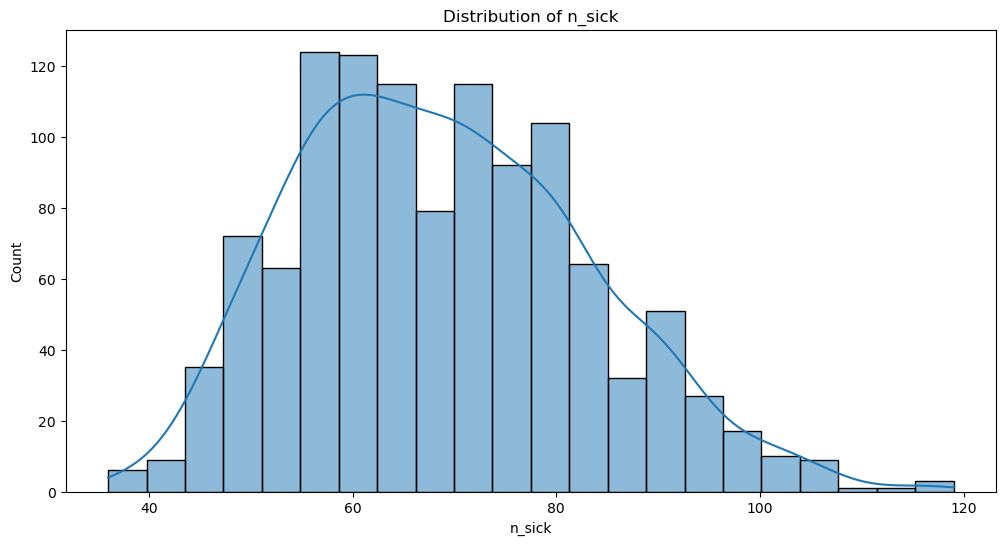

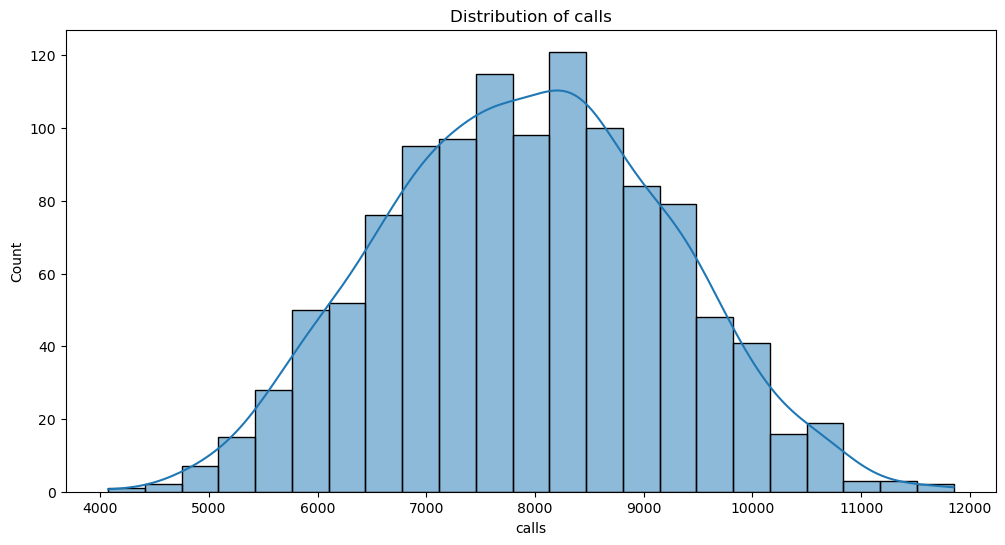

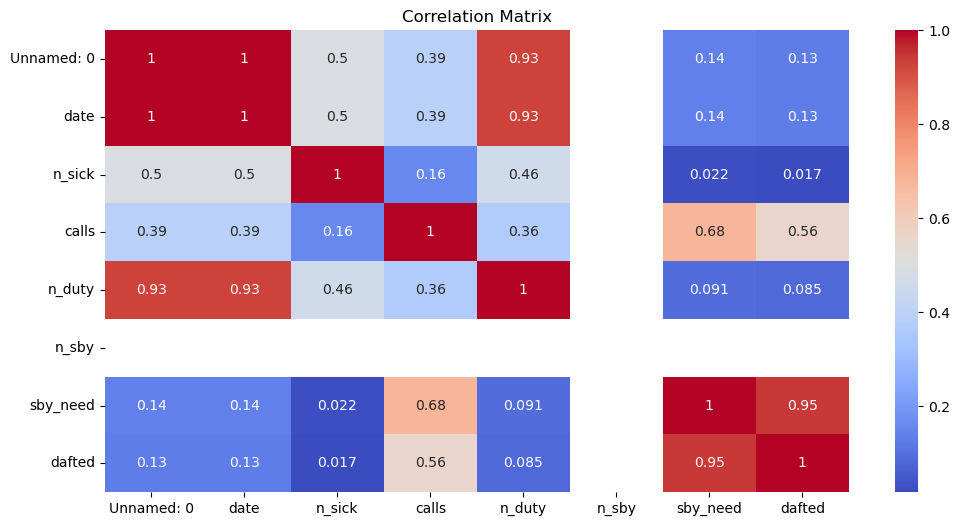

In [26]:
# Visualisierungen
plt.figure(figsize=(12, 6))
sns.histplot(df['n_sick'], kde=True)
plt.title('Distribution of n_sick')
plt.show()

plt.figure(figsize=(12, 6))
sns.histplot(df['calls'], kde=True)
plt.title('Distribution of calls')
plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Datenvorbereitung

In [34]:
working_df = df.copy(deep=True)

print("Number NaN values:", working_df.isna().sum())

# Umgang mit fehlenden Werten
working_df = working_df.dropna()

# Feature Engineering
working_df['month'] = working_df['date'].dt.month
working_df['day_of_week'] = working_df['date'].dt.dayofweek

# Datenaufteilung
from sklearn.model_selection import train_test_split

X = working_df[['calls', 'n_duty', 'n_sby', 'sby_need', 'dafted', 'month', 'day_of_week']]
y = working_df['n_sick']  # Annahme: n_sick soll vorhergesagt werden

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Number NaN values: Unnamed: 0    0
date          0
n_sick        0
calls         0
n_duty        0
n_sby         0
sby_need      0
dafted        0
dtype: int64


## Baseline-Modell

In [32]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline_model = DummyRegressor(strategy='mean')
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

print(f'Baseline MAE: {mean_absolute_error(y_test, y_pred_baseline)}')

Baseline MAE: 12.46238560570808


## Erstellung und Evaluation des Vorhersagemodells

Model MAE: 7.693878169449599
Best Model MAE: 7.510964253818184


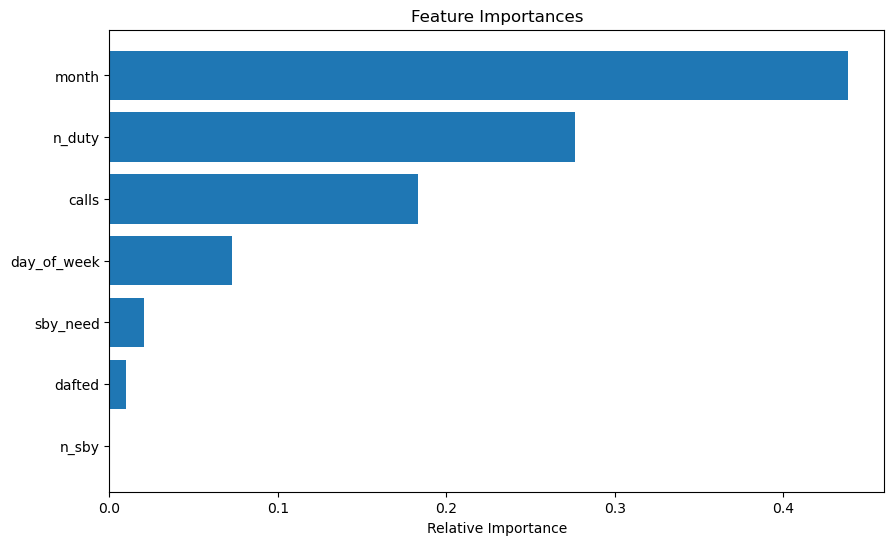

In [33]:
# Auswahl und Training eines Modells
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Model MAE: {mean_absolute_error(y_test, y_pred)}')

# Hyperparameter-Tuning (optional)
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(model, param_grid, cv=5, scoring='neg_mean_absolute_error')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print(f'Best Model MAE: {mean_absolute_error(y_test, y_pred_best)}')

# Visualisierung und Kommunikation der Ergebnisse

# Feature Importance
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()